# LGG Segmentation Dataset

This dataset contains brain MR images together with manual FLAIR abnormality segmentation masks. The images were obtained from The Cancer Imaging Archive (TCIA). They correspond to 110 patients included in The Cancer Genome Atlas (TCGA) lower-grade glioma collection with at least fluid-attenuated inversion recovery (FLAIR) sequence and genomic cluster data available. Tumor genomic clusters and patient data is provided in data.csv file.

All images are provided in `.tif` format with 3 channels per image. 
1. For 101 cases, 3 sequences are available, i.e. pre-contrast, FLAIR, post-contrast (in this order of channels).
2. For 9 cases, post-contrast sequence is missing.
3. For 6 cases, pre-contrast sequence is missing.
4. Missing sequences are replaced with FLAIR sequence to make all images 3-channel.
5. Masks are binary, 1-channel images. They segment FLAIR abnormality present in the FLAIR sequence (available for all cases).

The dataset is organized into 110 folders named after case ID that contains information about source institution. Each folder contains MR images with the following naming convention:

`TCGA_<institution-code>_<patient-id>_<slice-number>.tif`

Corresponding masks have a `_mask` suffix.

In [1]:
import os
from pathlib import Path

import pandas as pd

In [2]:
data_dir = Path("/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m")
csv_path = data_dir / "data.csv"

In [3]:
dirs = [item for item in os.listdir(data_dir) if "TCGA" in item]
images_data = []

for dir_name in dirs:
    dir_images = os.listdir(data_dir / dir_name)
    
    for image_name in dir_images:
        if "mask" in image_name:
            continue
    
        masked_image_name = f"{image_name[:-4]}_mask.tif"
        images_data.append([image_name, masked_image_name])

images_df = pd.DataFrame(images_data, columns=["Image", "Mask"])
images_df.head()

,Image,Mask
0,TCGA_DU_7010_19860307_45.tif,TCGA_DU_7010_19860307_45_mask.tif
1,TCGA_DU_7010_19860307_57.tif,TCGA_DU_7010_19860307_57_mask.tif
2,TCGA_DU_7010_19860307_33.tif,TCGA_DU_7010_19860307_33_mask.tif
3,TCGA_DU_7010_19860307_27.tif,TCGA_DU_7010_19860307_27_mask.tif
4,TCGA_DU_7010_19860307_52.tif,TCGA_DU_7010_19860307_52_mask.tif


# Dataset Creation

In [4]:
import cv2
import torch
from torch.utils.data import Dataset

In [50]:
class MRIDataset(Dataset):
    def __init__(self, path=data_dir):
        self.image_paths = []
        
        dirs = [item for item in os.listdir(data_dir) if "TCGA" in item]
        images_data = []
        
        for dir_name in dirs:
            dir_path = data_dir / dir_name
            dir_images = os.listdir(dir_path)
            
            for image_name in dir_images:
                if "mask" in image_name:
                    continue

                image_path = dir_path / image_name
                self.image_paths.append(image_path)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = str(self.image_paths[idx])
        mask_path = f"{image_path[:-4]}_mask.tif"

        image = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)
        mask  = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        image = torch.from_numpy(image).float().permute(2,0,1) / 255
        mask  = torch.from_numpy(mask).float()[None,:,:] / 255
        
        return image, mask

In [51]:
import matplotlib.pyplot as plt

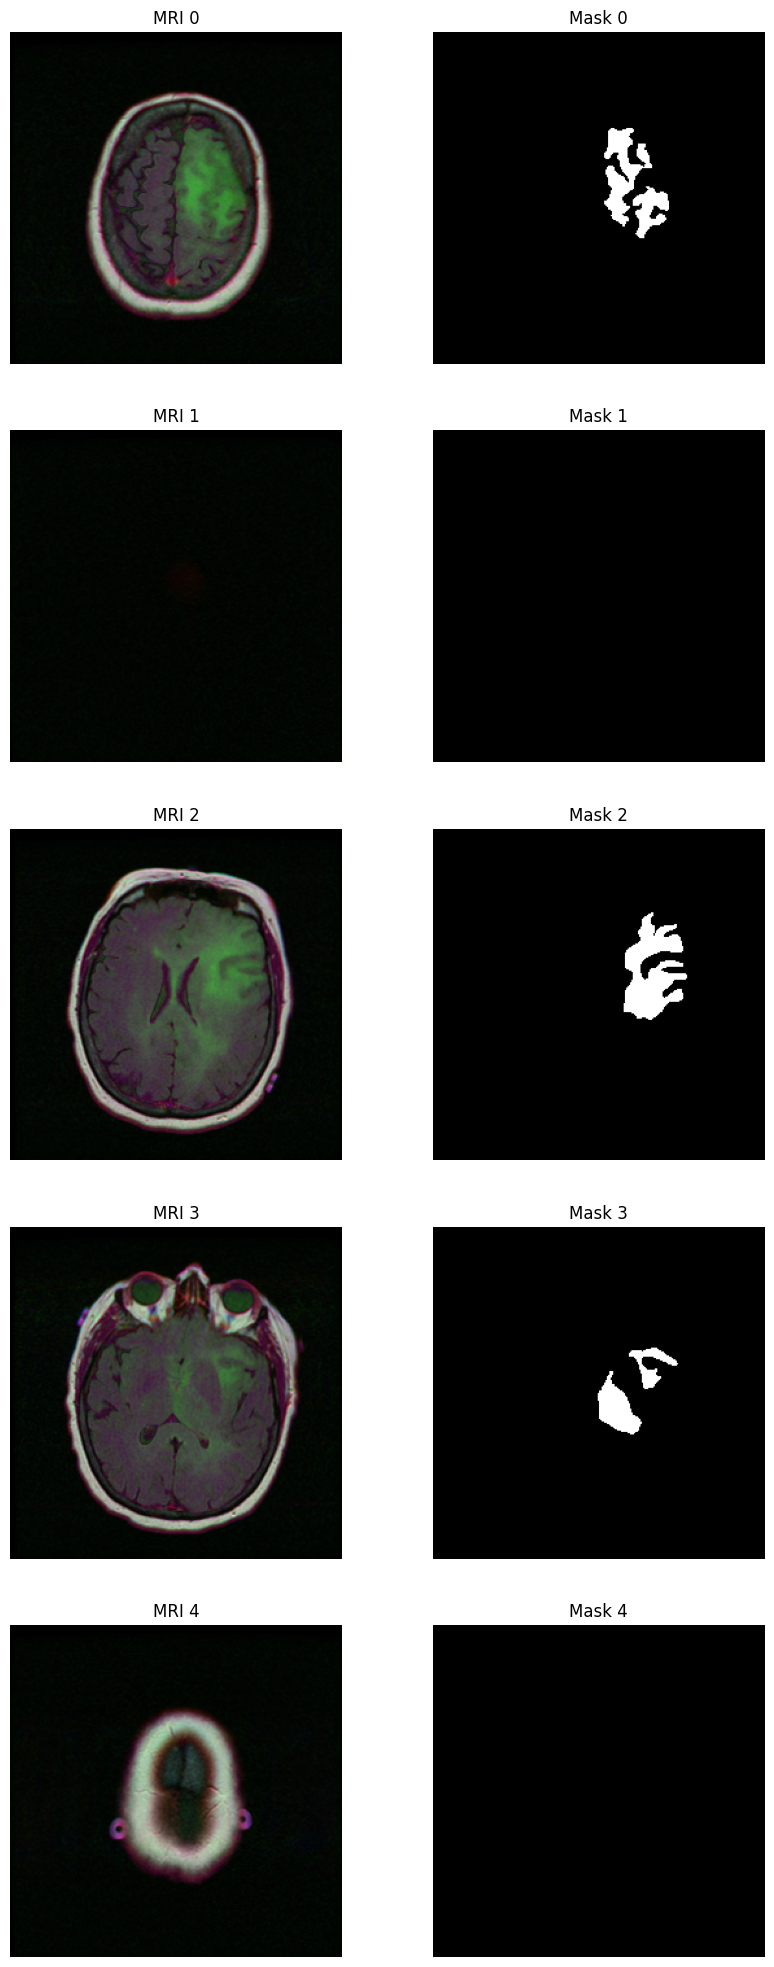

In [52]:
mri_dataset = MRIDataset()

def plot_mri_images(indices):
    nrows = len(indices)
    images_subset = [mri_dataset[idx] for idx in indices]
    fig, axes = plt.subplots(nrows,2,figsize=(10,nrows*5))
    
    for idx, (image, mask) in enumerate(images_subset):
        axes[idx][0].imshow(image.permute(1,2,0))
        axes[idx][1].imshow(mask.permute(1,2,0), cmap="gray")

        axes[idx][0].axis("off")
        axes[idx][1].axis("off")

        axes[idx][0].set_title(f"MRI {indices[idx]}")
        axes[idx][1].set_title(f"Mask {indices[idx]}")
        
    plt.show()

plot_mri_images(range(5))

# Basic EDA

In [53]:
import random
from tqdm.auto import tqdm

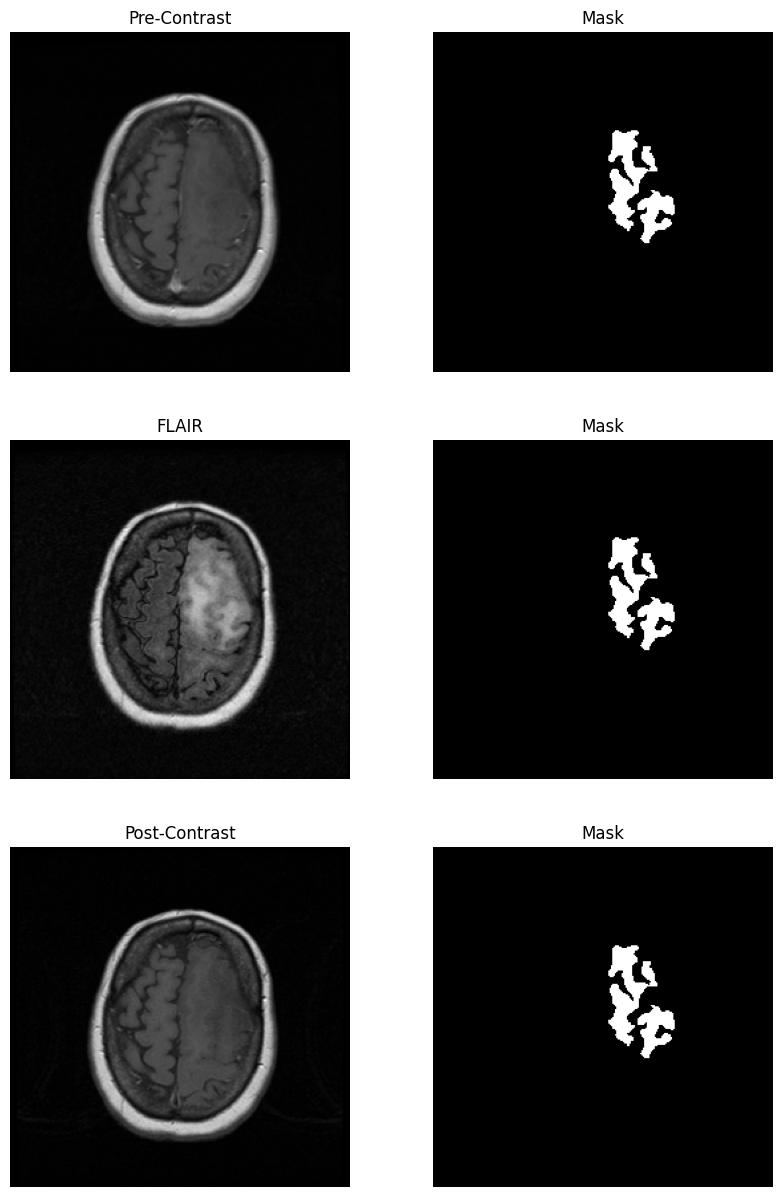

In [54]:
random.seed(42)
nrows = 5
indices = [random.randrange(0,len(mri_dataset)) for _ in range(nrows)]

def plot_sample_channels(sample, specific_channel=None):
    image, mask = sample
    nrows = 1 if specific_channel is not None else 3
    fig, axes = plt.subplots(nrows,2,figsize=(10,nrows*5))
    titles = ["Pre-Contrast", "FLAIR", "Post-Contrast"]

    if len(axes) != 3:
        axes = [axes]
    
    for idx in range(image.shape[0]):
        ax_idx = idx

        if specific_channel is not None:
            if idx != specific_channel:
                continue
            else:
                ax_idx = 0
        
        channel = image[idx]
        
        axes[ax_idx][0].imshow(channel, cmap="gray")
        axes[ax_idx][1].imshow(mask[0], cmap="gray")

        axes[ax_idx][0].axis("off")
        axes[ax_idx][1].axis("off")

        axes[ax_idx][0].set_title(titles[idx])
        axes[ax_idx][1].set_title("Mask")
    
    plt.show()

plot_sample_channels(mri_dataset[0])

In [55]:
image, mask = mri_dataset[0]

for channel_idx in range(image.shape[0]):
    channel = image[channel_idx]
    print(channel.sum())

tensor(6213.8398)
tensor(7064.1064)
tensor(5564.5146)


In [64]:
images_stats = {
    "pre_missing": [],
    "post_missing": [],
    "both_missing": [],
    "empty_background": [],
    "none_missing": [],
    "empty_mask": [],
    "tumour_mask": []
}

pbar = tqdm(range(len(mri_dataset)), desc="Finding incomplete images...")

for idx in pbar:
    image, mask = mri_dataset[idx]

    if image[1].max() == 0:
        images_stats["empty_background"].append(idx)
        continue
    
    pre_missing = torch.equal(image[0], image[1])
    post_missing = torch.equal(image[2], image[1])

    empty_mask = (mask.max() == 0).item()

    if pre_missing and post_missing:
        images_stats["both_missing"].append(idx)
    elif pre_missing:
        images_stats["pre_missing"].append(idx)
    elif post_missing:
        images_stats["post_missing"].append(idx)
    else:
        images_stats["none_missing"].append(idx)

    if empty_mask:
        images_stats["empty_mask"].append(idx)
    else:
        images_stats["tumour_mask"].append(idx)

print(f"Empty background in {len(images_stats["empty_background"])} images")
print(f"Pre-Contrast missing in {len(images_stats["pre_missing"])} images")
print(f"Post-Contrast missing in {len(images_stats["post_missing"])} images")
print(f"Both missing in {len(images_stats["both_missing"])} images")
print(f"None missing in {len(images_stats["none_missing"])} images")

print()
print(f"Empty mask in {len(images_stats["empty_mask"])} images")
print(f"Tumour mask in {len(images_stats["tumour_mask"])} images")

Finding incomplete images...:   0%|          | 0/3929 [00:00<?, ?it/s]

Empty background in 30 images
Pre-Contrast missing in 156 images
Post-Contrast missing in 0 images
Both missing in 300 images
None missing in 3443 images

Empty mask in 2526 images
Tumour mask in 1373 images


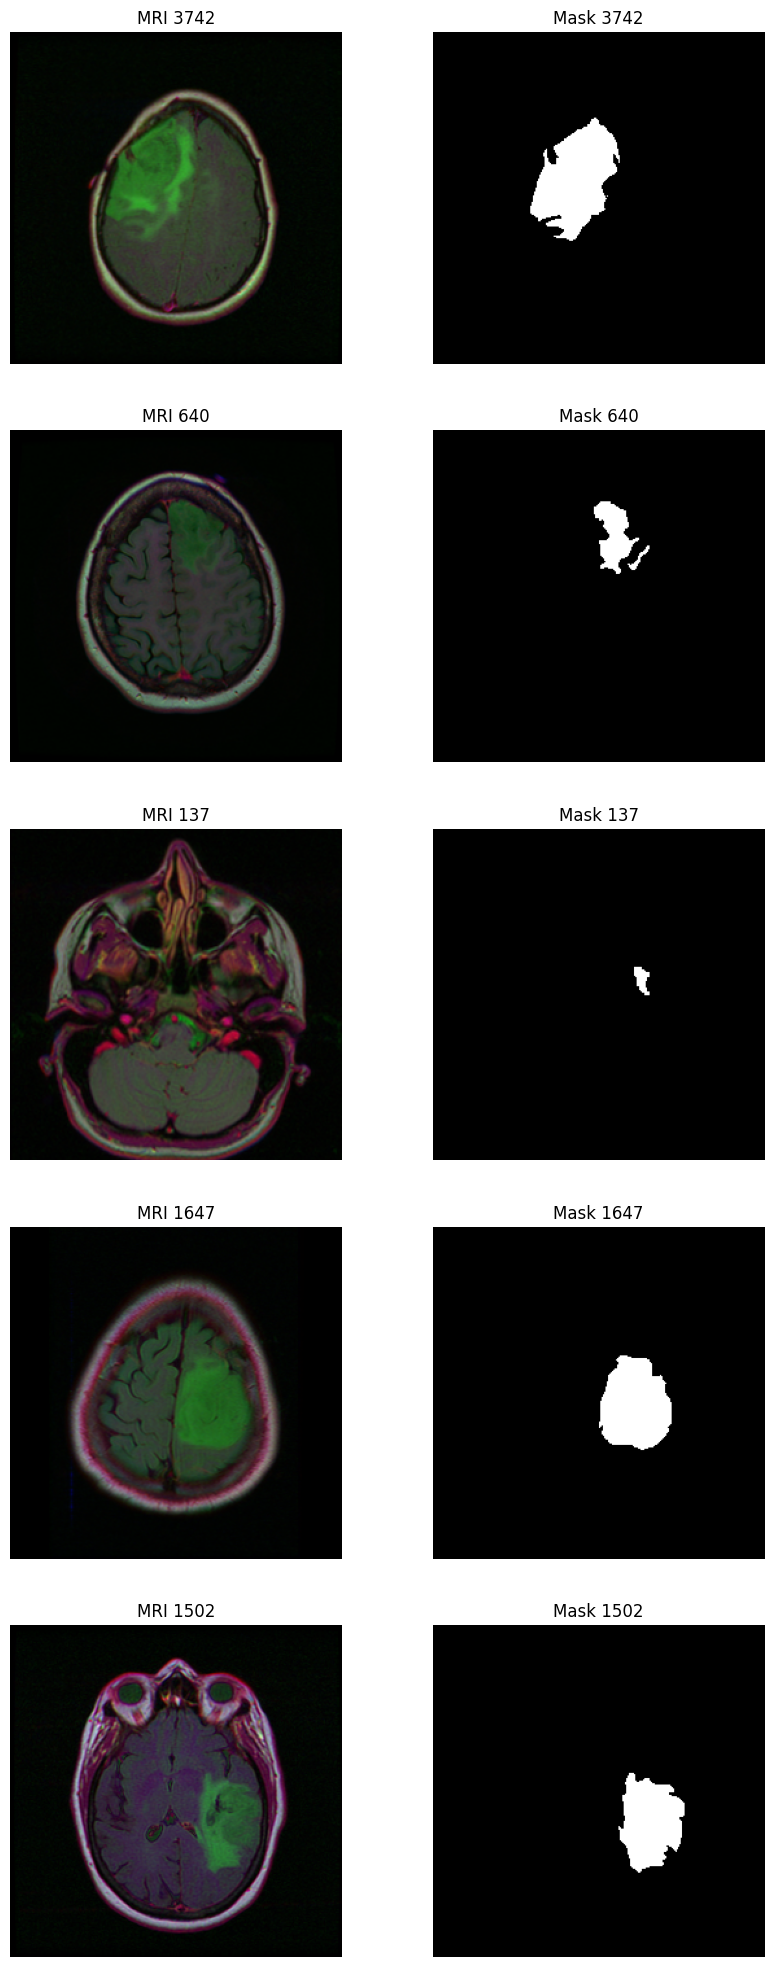

In [65]:
random.seed(42)
n_images = 5
indices  = [random.choice(images_stats["tumour_mask"]) for _ in range(n_images)]
plot_mri_images(indices)